# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np# importar librerías

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [3]:
plans.head()# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())# Cantidad de valores nulos)
print(usage.isna().mean())# Proporción de valores nulos)# cantidad de nulos para usage

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 

* Respuesta:
  - La columna city de users presenta 11.7% de nulos -> Zona intermedia, hay que evaluar si imputar o dejar nulo, según importancia en el análsis
  - La columna churn_date de user presenta 88.35% de nulos -> Representa clientes activos, por lo cual se debe dejar como está, no eliminar ni imputar.
  - La columna date de usage presenta 0.125% de nulos -> Significa una cantidad menor al 5%, de tal manera lo mas razonable es eliminar esas pocas filas
  - La columna duration de usage presenta 55.19% de nulos -> No son errores, corresponden a registros tipo "text" donde duration no aplica; se dejan como nulos.
  - La columna length de usage presenta 44.74% de nulos -> No son errores, corresponden a registros tipo "call" donde length no aplica; se dejan como nulos.
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
* Respuesta:
  - Las columnas son:
    city (11.7%) y churn_date (88.35%) en users; ademas date (0.125%), duration (55.19%) y length (44.74%) en usage.
  - Para: city, investigar/imputar o dejar según importancia (zona intermedia, 11.7%).
    churn_date, ignorar/dejar el nulo, porque indica cliente activo, no es un error.
    date, eliminar las filas (porcentaje mínimo, no se puede imputar una fecha de forma confiable).
    duration y length, ignorar/dejar como nulo, porque dependen del tipo de registro (call o text) y no aplican en cada caso.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
users[['user_id','age']]# explorar columnas numéricas de users


,user_id,age
0,10000,38
1,10001,53
2,10002,57
3,10003,69
4,10004,63
...,...,...
3995,13995,60
3996,13996,24
3997,13997,58
3998,13998,57


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [13]:
usage[['id', 'user_id']]# explorar columnas numéricas de usage

,id,user_id
0,1,10332
1,2,11458
2,3,11777
3,4,10682
4,5,12742
...,...,...
39995,39996,13497
39996,39997,10941
39997,39998,13038
39998,39999,10863


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [14]:
# explorar columnas categóricas de users
users[['city', 'plan']]


,city,plan
0,Medellín,Basico
1,?,Basico
2,CDMX,Basico
3,Bogotá,Premium
4,GDL,Basico
...,...,...
3995,Medellín,Basico
3996,Medellín,Premium
3997,Bogotá,Premium
3998,Bogotá,Basico


- La columna `city` ...
- La columna `plan` ...

In [15]:
# explorar columna categórica de usage
usage['type'] # completa el código

0        call
1        text
2        text
3        call
4        call
         ... 
39995    call
39996    call
39997    call
39998    text
39999    call
Name: type, Length: 40000, dtype: object

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- La columna donde encontre valores invalidos fue city en users con un sentinel "?"
- ¿Qué acción tomarías?
- La acción que tomaria seria cambiar el valor nulo "?" por un nulo real como NaN, para que pandas lo reconozca como falta de dato

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])# completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])# completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date']

0      2022-01-01 00:00:00.000000000
1      2022-01-01 06:34:17.914478619
2      2022-01-01 13:08:35.828957239
3      2022-01-01 19:42:53.743435858
4      2022-01-02 02:17:11.657914478
                    ...             
3995   2024-12-29 21:42:48.342085520
3996   2024-12-30 04:17:06.256564144
3997   2024-12-30 10:51:24.171042768
3998   2024-12-30 17:25:42.085521392
3999   2024-12-31 00:00:00.000000000
Name: reg_date, Length: 4000, dtype: datetime64[ns]

In [19]:
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

In [20]:
(users['reg_date'].dt.year > 2024).sum()

40

In [21]:
(users['reg_date'].dt.year > 2024).sum()*100/len(users)

1.0

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [22]:
# Revisar los años presentes en `date` de usage
usage['date']

0       2024-01-01 00:00:00.000000000
1       2024-01-01 00:06:30.969774244
2       2024-01-01 00:13:01.939548488
3       2024-01-01 00:19:32.909322733
4       2024-01-01 00:26:03.879096977
                     ...             
39995   2024-06-29 23:33:56.120903022
39996   2024-06-29 23:40:27.090677266
39997   2024-06-29 23:46:58.060451510
39998   2024-06-29 23:53:29.030225754
39999   2024-06-30 00:00:00.000000000
Name: date, Length: 40000, dtype: datetime64[ns]

In [23]:
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Para la base de datos de users la columna reg_date si, dado que son datos hasta el año 2024 y años anteriores, no años como 2026 que viene despues, lo cual es imposible, no deberia aparecer al momento de guardar los datos
- ¿Qué harías con ellas?
- Se detectaron 40 filas (0,1%) con el valor "2026" para la columna reg_Date, lo cual no es posible dado que la informacion maxima registrada es hasta el año 2024, no tiene sentido ver años mayores. Lo que se hara con estos valores "2026" es eliminar este porcentaje de los datos (40 filas), pues este error puede distorsionar los cálculos de antiguedad/retención

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [24]:
# Reemplazar -999 por la mediana de age
users['age'] = users['age'].replace(-999, np.nan)
age_mediana = users['age'].median()
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [25]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', np.nan)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [26]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date']
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT
# Verificar cambios
print(users['reg_date'].describe())

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [27]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [28]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

-Los nulos en duration son a causa de que en esta columna al filtrarla por tipo muestra que para la categoria "text" hay 22076 valores nulos, es decir todos, ya que un mensaje de texto no tiene duracion sino valor de length.
 Por otro lado en length los 17896 nulos se presentan debido a que al filtrarlo por typo se obtiene que una llamada no tendria un valor de length sino de duracion.
 
 De tal forma los nulos de "duration" y "length" son MAR: Su ausencia depende por completo de la variable type. Una llamada se mide por duración y un mensaje por longitud, por lo que el otro campo no aplica y no corresponde a información perdida.

Asi pues, se decide dejar los nulos como NaN, sin imputar ni eliminar filas


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [29]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration', 'length']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration,length
0,10000,7,3,23.70,258.0
1,10001,5,10,33.18,226.0
2,10002,5,2,10.74,225.0


In [30]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text': 'cantidad_mensajes', 'is_call': 'cantidad_llamadas', 
                                     'duration':'duracion_llamada', 'length': 'caracteres_mensajes'})
# observar resultado
usage_agg.head(3)

,user_id,cantidad_mensajes,cantidad_llamadas,duracion_llamada,caracteres_mensajes
0,10000,7,3,23.70,258.0
1,10001,5,10,33.18,226.0
2,10002,5,2,10.74,225.0


In [31]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how = 'left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cantidad_mensajes,cantidad_llamadas,duracion_llamada,caracteres_mensajes
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,258.0
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,226.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,225.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,530.0
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,229.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [32]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cantidad_mensajes,cantidad_llamadas,duracion_llamada,caracteres_mensajes
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054,288.128032
std,1154.844867,17.689919,2.358416,2.144238,18.168095,180.906841
min,10000.000000,18.000000,0.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000,184.000000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000,268.000000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000,361.000000
max,13999.000000,79.000000,17.000000,15.000000,155.690000,2028.000000


In [33]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

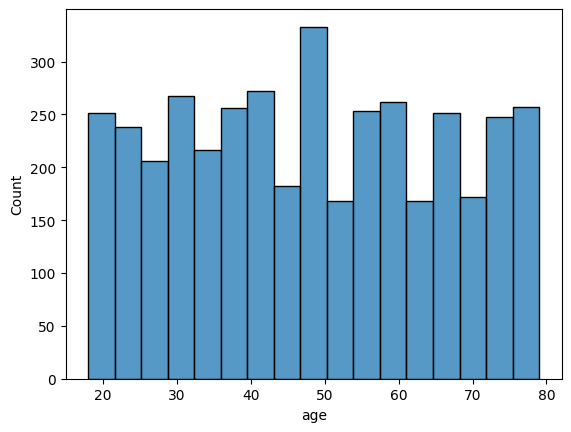

In [34]:
# Histograma para visualizar la edad (age)
sns.histplot(users['age'])
plt.show()

💡Insights: 
- Distribución uniforma en el rango general, sin sesgo marcado. Con un pico (moda) notable alrededor de los 48-50 años.

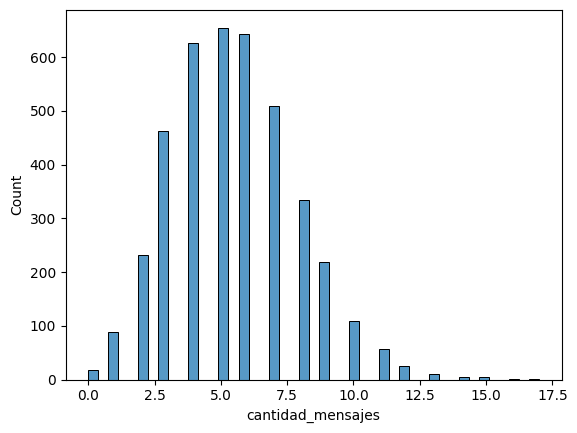

In [35]:
# Histograma para visualizar la cant_mensajes
sns.histplot(user_profile['cantidad_mensajes'])
plt.show()

💡Insights: 
- Sesgo hacia la derecha, como la asimetría es leve, la mediana y la media son similares, pero se prefiere la mediana como medida de resumen por su robustez.

<AxesSubplot:xlabel='cantidad_llamadas', ylabel='Count'>

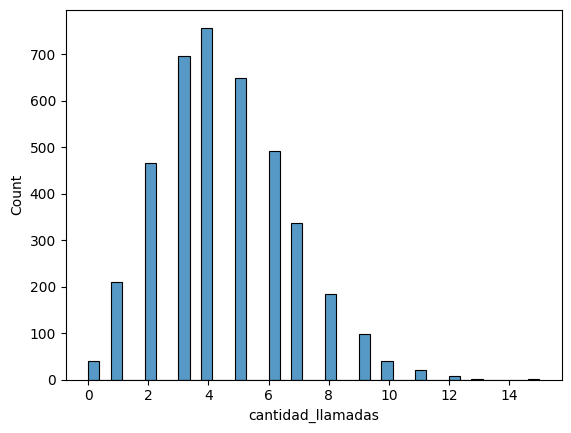

In [36]:
# Histograma para visualizar la cant_llamadas
sns.histplot(user_profile['cantidad_llamadas'])

💡Insights: 
- Distribución es unimodal con sesgo positivo, con la mayoría de los usuarios realizando entre 2 y 6 llamadas, concentrándose la moda en 4. Se observa un usuario atípico con casi 14-15 llamadas, muy alejado del resto, lo que podría indicar un caso de soporte técnico recurrente, quejas o reclamos.

<AxesSubplot:xlabel='duracion_llamada', ylabel='Count'>

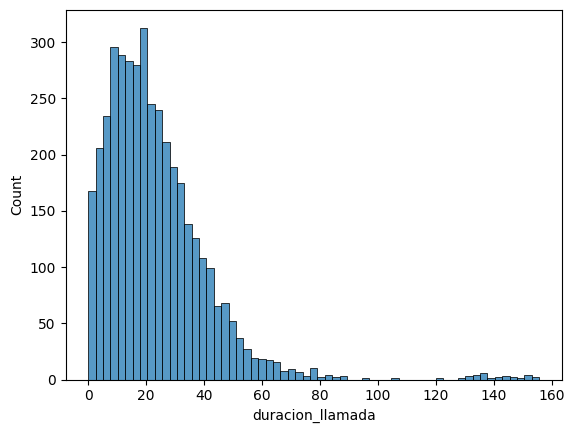

In [37]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(user_profile['duracion_llamada'])

💡Insights: 
- Se observa una mayor zona de concentración entre 10 y 30 minutos de llamada, con un sesgo a la derecha (asimetría positiva). Además, se identifica un pequeño grupo de outliers entre 130 y 160 minutos, claramente separado del resto de los datos, los cuales habría que investigar para determinar si corresponden a llamadas genuinamente largas o a errores de registro.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

In [38]:
user_profile.columns

Index(['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan',
       'churn_date', 'cantidad_mensajes', 'cantidad_llamadas',
       'duracion_llamada', 'caracteres_mensajes'],
      dtype='object')

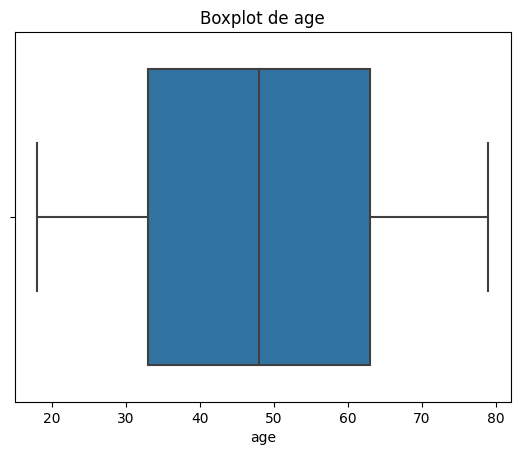

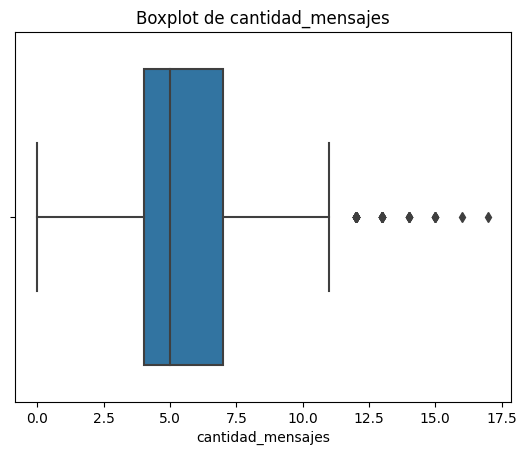

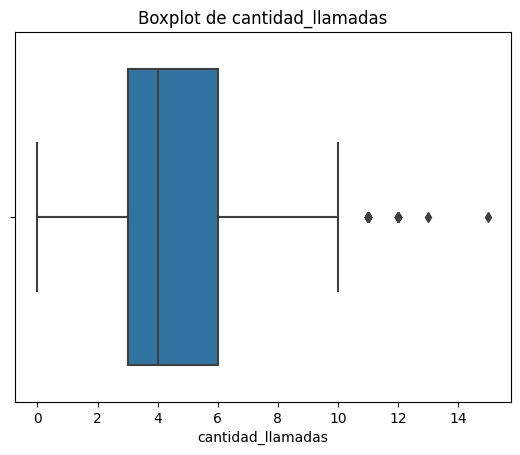

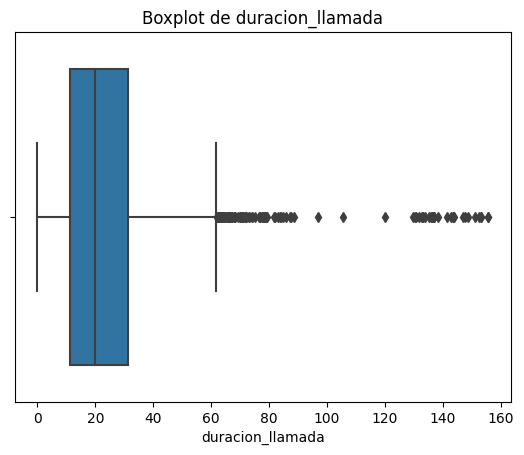

In [39]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cantidad_mensajes', 'cantidad_llamadas', 'duracion_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot de {col}')
    plt.show()


💡Insights: 
1. age: La edad va de 18 a 79 años, con mediana 48 % central entre 33 y 63. No hay valores atípicos, por lo que no existen edades imposibles ni sentinels (0, 999, etc.). El rango comienza en 18, consistente con una base de clientes adultos. Se decide conservar la columna sin modificaciones y usarla para segmentar por grupos de edad.
2. cantidad_mensajes: Uso homogéneo con una cola leve. El 50 % de los usuarios envía entre 4 y 7 mensajes (mediana 5). Los outliers aparecen desde 12 mensajes (límite IQR = 11) y llegan hasta 17, de forma continua y sin saltos. Esta continuidad indica usuarios intensivos legítimos,
no errores de registro. Por ello se opta por conservarlos y categorizarlos como "usuarios de alta mensajería" para perfilarlos por plan, edad y país.

3. cantidad_llamadas: Comportamiento estable con un caso aislado. La mediana es 4 llamadas y el 50 % central se ubica entre 3 y 6. Los outliers parten desde 11 llamadas (límite IQR = 10). Destaca un valor aislado en 15, separado de los demás. Son muy pocos usuarios, por lo que no afectan los resúmenes generales. De esta forma hay que revisar individualmente al usuario con 15 llamadas (plan, país, duración total, estado de churn) para determinar si es uso intensivo real o un registro anómalo.

4. duracion_llamada`: La variable más crítica del análisis. Presenta fuerte sesgo positivo y numerosos outliers (desde ≈ 62 hasta ≈ 155). Se distinguen dos grupos: una cola densa entre ≈ 62 y 90 (usuarios de alto consumo, comportamiento natural de una distribución sesgada) y un grupo compacto y separado entre ≈ 130 y 155, que se considera el comportamiento verdaderamente atípico. Estos valores desplazan la media por encima de la mediana y distorsionarían cualquier promedio. Por lo cual no se eliminaran automáticamente; usar la mediana como medida de resumen, y perfilar el grupo aislado (plan, edad, país, churn) para clasificarlo como uso legítimo, posible fraude o error de registro.


In [40]:
# Calcular límites con el método IQR
columnas_limites = [ 'cantidad_mensajes', 'cantidad_llamadas', 'duracion_llamada']
for col in columnas_limites:
    Q1 =  user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    límite_inferior = Q1 - 1.5 * IQR
    límite_superior = Q3 + 1.5 * IQR
    print('Para', col, 'el límite inferior es', límite_inferior, 'y el superior es', límite_superior)

Para cantidad_mensajes el límite inferior es -0.5 y el superior es 11.5
Para cantidad_llamadas el límite inferior es -1.5 y el superior es 10.5
Para duracion_llamada el límite inferior es -19.322500000000005 y el superior es 61.8575


In [41]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cantidad_mensajes,cantidad_llamadas,duracion_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
  El máximo (17) supera el límite superior (11.5), pero la media (5.52) y la mediana (5) son casi iguales, así que su efecto sobre el análisis es mínimo. Los valores altos aparecen de forma continua y son plausibles (12 a 17 mensajes), lo que descarta errores de registro. Por lo cual se mantienen los outliers pues representan usuarios de alta mensajería, un segmento útil para el negocio.
  
- cant_llamadas: mantener o no outliers, porqué?
  El máximo (15) supera el límite (10.5) de forma moderada y la media (4.48) está muy cerca de la mediana (4), por lo que no distorsionan los resultados. Los outliers son conteos reales y posibles, y por eso se conservan. Se revisará aparte al usuario con 15 llamadas para confirmar que es uso intensivo y no un registro anómalo.

- cant_minutos_llamada: mantener o no outliers, porqué?
  Se mantienen los outliers. El máximo (155.69) es unas 2,5 veces el límite superior (61.86) y la media (23.32) supera a la mediana (19.78), por lo que es la única variable donde los valores extremos sí influyen en el promedio. Aun así, no se eliminan ni se recortan: no hay duraciones negativas ni imposibles que indiquen errores, y estos usuarios pueden representar a los clientes de mayor consumo, justo el comportamiento atípico que el proyecto busca identificar. Para que no distorsionen los resultados, se usará la mediana y no la media como medida de resumen, se marcarán en una columna aparte "es_outlier_duracion" para compararlos con el resto, y se perfilarán por plan, edad y país antes de concluir si corresponden a uso legítimo, posible fraude o error de captura.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [42]:
# Crear columna grupo_uso
condiciones = [ (user_profile['cantidad_llamadas'] < 5) & (user_profile['cantidad_mensajes'] < 5), 
    (user_profile['cantidad_llamadas'] < 10) & (user_profile['cantidad_mensajes'] < 10)]
categorias = ['Bajo uso', 'Uso medio']
user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cantidad_mensajes,cantidad_llamadas,duracion_llamada,caracteres_mensajes,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,258.0,Uso medio
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,226.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,225.0,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,530.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,229.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
# Crear columna grupo_edad
condiciones = [ (user_profile['age'] < 30) , (user_profile['age'] < 60)]
categorias = ['Joven', 'Adulto']
user_profile ['grupo_edad'] = np.select(condiciones, categorias, default='Adulto Mayor')

In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cantidad_mensajes,cantidad_llamadas,duracion_llamada,caracteres_mensajes,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,258.0,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,226.0,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,225.0,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,530.0,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,229.0,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

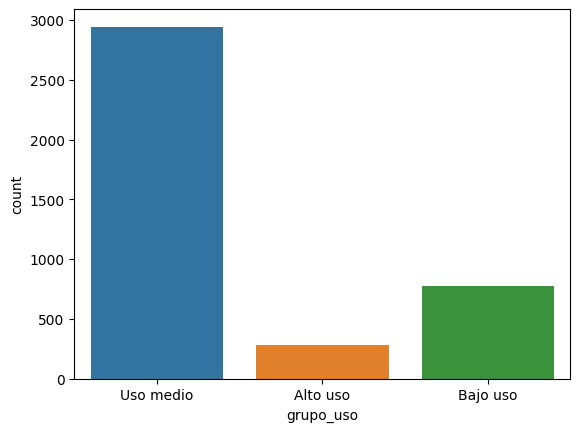

In [46]:
# Visualización de los segmentos por uso

sns.countplot(x = 'grupo_uso', data = user_profile)
plt.show()


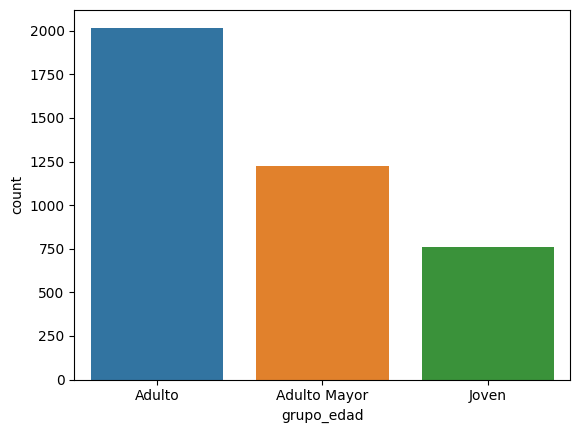

In [47]:
# Visualización de los segmentos por edad
sns.countplot(x = 'grupo_edad', data = user_profile)
plt.show()


In [48]:
# Mediana de uso por grupo de edad
orden = ['Joven', 'Adulto', 'Adulto Mayor']
resumen = (user_profile.groupby('grupo_edad')
           [['cantidad_llamadas', 'cantidad_mensajes', 'duracion_llamada']]
           .median().loc[orden])
print(resumen)

# Porcentaje exacto de cada grupo
print(user_profile['grupo_edad'].value_counts(normalize=True).round(3))

# Distribución de nivel de uso dentro de cada grupo de edad
print(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index').round(3))

              cantidad_llamadas  cantidad_mensajes  duracion_llamada
grupo_edad                                                          
Joven                       4.0                5.0            19.155
Adulto                      4.0                5.0            20.040
Adulto Mayor                4.0                5.0            19.660
Adulto          0.504
Adulto Mayor    0.306
Joven           0.190
Name: grupo_edad, dtype: float64
grupo_uso     Alto uso  Bajo uso  Uso medio
grupo_edad                                 
Adulto           0.076     0.180      0.743
Adulto Mayor     0.061     0.210      0.729
Joven            0.067     0.207      0.726


In [49]:
orden_uso = ['Bajo uso', 'Uso medio', 'Alto uso']
print(user_profile.groupby('grupo_uso')[['cantidad_llamadas','cantidad_mensajes','duracion_llamada']].median().loc[orden_uso])
print(pd.crosstab(user_profile['plan'], user_profile['grupo_uso'], normalize='index').round(3))
user_profile['churn'] = user_profile['churn_date'].notna()
print(user_profile.groupby('grupo_uso')['churn'].mean().round(3).loc[orden_uso])

           cantidad_llamadas  cantidad_mensajes  duracion_llamada
grupo_uso                                                        
Bajo uso                 3.0                3.0             12.76
Uso medio                5.0                6.0             21.58
Alto uso                 5.0               10.0             25.93
grupo_uso  Alto uso  Bajo uso  Uso medio
plan                                    
Basico        0.072     0.197      0.731
Premium       0.066     0.189      0.744
grupo_uso
Bajo uso     0.114
Uso medio    0.115
Alto uso     0.140
Name: churn, dtype: float64



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- city (users): 469 nulos (11,7 % de los 4.000 usuarios). Impide asignar país a esos clientes, por lo que se mantuvieron como categoría "Desconocida" en lugar de eliminarlos.
- churn_date (users): 3.534 nulos (88,35 %). No es un error: indica clientes activos. Se usó para identificar ~466 clientes que abandonaron (11,65 %).
- duration y length (usage): "duration" es nulo en todos los mensajes (22.076 filas) y "length" es nulo en todas las llamadas (17.896 filas). Son nulos estructurales (el campo no aplica al tipo de actividad), por lo que se dejaron como NaN para no distorsionar promedios.
- Valores atípicos: "duracion_llamada" llega a 155,69 frente a un límite IQR de 61,86; "cantidad_mensajes" llega a 17 (límite 11,5) y "cantidad_llamadas" a 15 (límite 10,5). Se conservaron y se marcaron para analizarlos por separado.
- reg_date (users): Se detectaron 40 filas (1 %) con año de registro 2026, un valor imposible porque los datos llegan solo hasta 2024. Esto puede significar un error de captura, no de un cliente real con fecha futura. Asi pues, se opta por eliminar estas 40 filas. Son una proporción muy pequeña de la base, por lo que su exclusión no sesga los resultados, y mantenerlas distorsionaría los cálculos.

🔍 **Segmentos por Edad**

- Se definieron tres grupos: Joven (menores de 30 años), Adulto (30 a 59 años) y Adulto Mayor (60 años o más). La base se concentra en Adultos (2.000 usuarios, 50.4 %), seguida por Adultos Mayores (1.200, 30.6 %) y Jóvenes (760, 19 %). Los jóvenes son el segmento menos representado.
- El consumo es prácticamente igual entre grupos de edad. Los tres tienen una mediana de 4 llamadas y 5 mensajes, y la duración mediana de llamada es de 19,2 minutos (Jóvenes), 20,0 (Adultos) y 19,7 (Adultos Mayores), una diferencia menor a 1 minuto. La edad, por sí sola, no explica cuánto usa un cliente el servicio.
- La distribución por nivel de uso también es similar: Entre el 72,6 % y el 74,3 % de cada grupo es de Uso medio. Los Adultos son el grupo con mayor Alto uso (7,6 %) y menor Bajo uso (18,0 %), mientras que los Adultos Mayores (21,0 %) y los Jóvenes (20,7 %) tienen algo más de Bajo uso. Las diferencias son de pocos puntos porcentuales, por lo que deben leerse como tendencias leves y no como perfiles distintos.


📊 **Segmentos por Nivel de Uso**

- La base se concentra en el Uso medio: 2.940 usuarios (73 %). Le siguen Bajo uso con 780 (19 %) y Alto uso con 280 (7,0 %). Aproximadamente 3 de cada 4 clientes tienen un consumo moderado.
- Los grupos se diferencian claramente por su consumo real. Bajo uso tiene una mediana de 3 llamadas, 3 mensajes y 12,8 minutos; Uso medio, de 5 llamadas, 6 mensajes y 21,6 minutos; y Alto uso, de 5 llamadas, 10 mensajes y 25,9 minutos. La mediana de mensajes (10) indica que Alto uso se explica sobre todo por mensajería intensiva, más que por llamadas.
- El nivel de uso no se distribuye distinto entre planes. Básico y Premium tienen casi la misma composición: Uso medio 73,1 % frente a 74,4 %, Bajo uso 19,7 % frente a 18,9 % y Alto uso 7,2 % frente a 6,6 %. Los clientes Premium no consumen más que los Básico.
- El churn es similar entre niveles de uso: 11,4 % en Bajo uso, 11,5 % en Uso medio y 14,0 % en Alto uso. El bajo consumo no predice el abandono. Alto uso presenta el valor más alto, pero con solo ~280 usuarios la diferencia debe tomarse como tendencia a monitorear y no como hallazgo concluyente.
- grupo_uso se definió con conteos de llamadas y mensajes, no con la duración, por lo que un cliente con pocas llamadas muy largas puede quedar en Bajo o Medio uso aunque consuma muchos minutos.


💡 **Recomendaciones**

1. Rediseñar la diferencia entre Básico y Premium. Ambos planes tienen el mismo perfil de consumo (Uso medio 73,1 % vs 74,4 %; Alto uso 7,2 % vs 6,6 %), es decir, pagar más no se traduce en usar más. Comparar el uso real con los minutos, mensajes y GB incluidos y ajustar beneficios o precio de Premium hacia valor percibido (datos, roaming, servicios adicionales).

2. Retener al segmento de Alto uso. Es el de mayor churn (14,0 % vs ~11,5 % del resto) y el de mayor consumo (mediana de 10 mensajes y 25,9 minutos). Activar alertas cuando se acerquen al límite del plan y ofrecer beneficios personalizados antes de que abandonen. Con solo 280 clientes, es una señal a monitorear y no una conclusión firme.

3. Crear un paquete de mensajería ampliada. Alto uso se explica más por mensajes (mediana de 10) que por llamadas (mediana de 5). Un paquete con mensajes ampliados o ilimitados evitaría cargos extra y mejoraría su satisfacción.

4. Segmentar campañas por comportamiento, no por edad. Las medianas de llamadas (4) y mensajes (5) son idénticas entre Jóvenes, Adultos y Adultos Mayores. La edad sirve para el canal de comunicación, no para diseñar planes.

5. Validar las duraciones extremas (130-155 min). Perfilarlas por plan, edad y país con fraude y operaciones, y definir alertas automáticas. Si son clientes legítimos de uso profesional, son candidatos a un plan empresarial.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`